# 재활용 객체 탐지 - 도메인 특화



In [ ]:
import sys, subprocess
# 원본 실행 로그의 버전으로 고정. 새 버전 사용 시 아래 버전을 변경하고 재검증하세요.
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                       'ultralytics==8.4.131', 'pyyaml', 'pandas', 'pillow', 'matplotlib'])
try:
    import google.colab
    colab = True
except ImportError:
    colab = False
if colab:
    from google.colab import drive
    drive.mount('/content/drive')
from pathlib import Path
import shutil, zipfile, hashlib, json, math, random
import numpy as np
from collections import Counter
from datetime import datetime
import yaml, torch, ultralytics, pandas as pd
from PIL import Image, ImageDraw
from IPython.display import display
from ultralytics import YOLO
print('Ultralytics:', ultralytics.__version__, '| GPU:', torch.cuda.is_available())

Mounted at /content/drive
Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
Ultralytics: 8.4.131 | GPU: True


## 1. 두 ZIP 경로와 학습 설정

In [ ]:
CLASSES = ['PAPER', 'CAN', 'PET', 'VINYL']
if colab:
    OLD_DATASET_ZIP = '/content/drive/MyDrive/ai/final/model_specific_domain3/dataset.zip'
    NEW_DATASET_ZIP = '/content/drive/MyDrive/ai/final/model_specific_domain3/specific_data2.zip'  # 필수: 새 ZIP의 실제 Drive 경로
    WORK_ROOT = Path('/content/recycle_work')
    SAVE_ROOT = Path('/content/drive/MyDrive/ai/final/model_specific_domain3/runs')
else:
    OLD_DATASET_ZIP = './dataset.zip'
    NEW_DATASET_ZIP = ''  # 필수: 새 ZIP 경로
    WORK_ROOT = Path('./recycle_work').resolve()
    SAVE_ROOT = Path('./save/recycle').resolve()
SOURCES = [('old', OLD_DATASET_ZIP), ('new', NEW_DATASET_ZIP)]
MODEL = 'yolo11s.pt'
IMGSZ, BATCH, EPOCHS = 832, 8, 200  # 두 모델을 같은 조건에서 비교
DEPLOY_IMGSZ = 640  # 평가 / 추론 / 고정 ONNX 입력
SEED = 42
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
ALLOW_CPU_TRAIN = False
INFER_CONF, MATCH_IOU = 0.25, 0.50
EXPORT_ONNX = True

## 2. 안전한 압축 해제 · 클래스 매핑 · 라벨 검증 · 병합


### EXIF 파일별 검토 — 병합 전에 실행
회전 정보가 있는 사진만 A/B 비교합니다.


In [ ]:
from PIL import ImageOps
import io
import ipywidgets as widgets

EXIF_REVIEW_DIR = SAVE_ROOT / 'exif_review'
EXIF_REVIEW_DIR.mkdir(parents=True, exist_ok=True)
EXIF_CHOICES_PATH = EXIF_REVIEW_DIR / 'choices.json'
EXIF_CHOICES = json.loads(EXIF_CHOICES_PATH.read_text(encoding='utf-8')) if EXIF_CHOICES_PATH.exists() else {}
EXIF_ITEMS = []
REVIEW_EXTS = {'.jpg','.jpeg','.png','.bmp','.webp','.tif','.tiff'}

def exif_key(tag, image_bytes, label_bytes):
    # 이미지 또는 라벨이 바뀌면 이전 선택을 재사용하지 않음
    return tag + ':' + hashlib.sha256(image_bytes).hexdigest() + ':' + hashlib.sha256(label_bytes).hexdigest()

def exif_rgb(im, choice):
    if choice == 'A':
        return im.convert('RGB')
    if choice == 'B':
        return ImageOps.exif_transpose(im).convert('RGB')
    raise ValueError('EXIF A/B 선택 필요')

for tag, zp in SOURCES:
    if not zp or not Path(zp).is_file():
        raise FileNotFoundError(f'{tag} ZIP 경로 확인: {zp}')
    with zipfile.ZipFile(zp) as z:
        names=set(z.namelist())
        for member in sorted(names):
            if Path(member).suffix.lower() not in REVIEW_EXTS: continue
            image_bytes=z.read(member)
            with Image.open(io.BytesIO(image_bytes)) as im:
                orientation=im.getexif().get(274,1)
                if orientation == 1: continue
            parts=list(Path(member).with_suffix('.txt').parts)
            candidates=[Path(*parts).as_posix()]
            if 'images' in parts:
                parts[parts.index('images')]='labels'
                candidates.append(Path(*parts).as_posix())
            labels=[n for n in dict.fromkeys(candidates) if n in names]
            if len(labels)!=1:
                raise ValueError(f'EXIF 검토용 TXT를 하나로 찾지 못했습니다: {member}, {labels}')
            label_bytes=z.read(labels[0])
            key=exif_key(tag,image_bytes,label_bytes)
            EXIF_ITEMS.append(dict(key=key,source=tag,zip=str(zp),member=member,label=labels[0],orientation=orientation))

def save_exif_choice(key, value):
    EXIF_CHOICES[key]=value
    tmp=EXIF_CHOICES_PATH.with_suffix('.tmp')
    tmp.write_text(json.dumps(EXIF_CHOICES,ensure_ascii=False,indent=2),encoding='utf-8')
    tmp.replace(EXIF_CHOICES_PATH)

def require_exif_review():
    pending=[r['member'] for r in EXIF_ITEMS if EXIF_CHOICES.get(r['key']) not in ('A','B','SKIP')]
    if pending:
        raise ValueError(f'EXIF 미확인 {len(pending)}장. 위 검토 셀에서 모두 선택한 뒤 병합 셀 재실행: {pending[:5]}')

def show_exif_page(page=1):
    start=(int(page)-1)*6
    for item in EXIF_ITEMS[start:start+6]:
        with zipfile.ZipFile(item['zip']) as z:
            image_bytes=z.read(item['member'])
            label_text=z.read(item['label']).decode('utf-8-sig')
        print(item['source'], item['member'], '| EXIF:',item['orientation'])
        panels=[]
        for choice in ['A','B']:
            with Image.open(io.BytesIO(image_bytes)) as im:
                canvas=exif_rgb(im,choice)
            draw=ImageDraw.Draw(canvas)
            W,H=canvas.size
            for line in label_text.splitlines():
                if not line.strip(): continue
                values=list(map(float,line.split()))
                if len(values)!=5: raise ValueError(f"잘못된 detection TXT: {item['label']}")
                cid,x,y,w,h=values
                xy=((x-w/2)*W,(y-h/2)*H,(x+w/2)*W,(y+h/2)*H)
                draw.rectangle(xy,outline='red',width=max(2,W//200))
                draw.text(xy[:2],f'ID {int(cid)}',fill='red')
            canvas.thumbnail((480,480))
            panel=Image.new('RGB',(500,520),'white')
            panel.paste(canvas,(10,30))
            ImageDraw.Draw(panel).text((10,10),choice,fill='black')
            panels.append(panel)
        pair=Image.new('RGB',(1000,520),'white')
        pair.paste(panels[0],(0,0)); pair.paste(panels[1],(500,0))
        display(pair)
        dropdown=widgets.Dropdown(
            options=[('미확인',''),('A: 원본 픽셀에 박스가 맞음','A'),
                     ('B: EXIF 회전 후 박스가 맞음','B'),('둘 다 틀림/판단 불가: 이번 학습에서 제외','SKIP')],
            value=EXIF_CHOICES.get(item['key'],''),layout=widgets.Layout(width='550px'))
        status=widgets.Label()
        def changed(change,key=item['key'],status=status):
            if change['name']=='value':
                save_exif_choice(key,change['new'])
                status.value='저장됨: '+(change['new'] or '미확인')
        dropdown.observe(changed,names='value')
        display(dropdown,status)
    print('선택은 Drive에 자동 저장됩니다. 모든 페이지 확인 후 아래 병합 셀을 실행하세요.')

print('EXIF 확인 대상:',len(EXIF_ITEMS),'장 | 저장:',EXIF_CHOICES_PATH)
print('A/B 모두 박스가 맞으면 물체 방향과 실제 라벨링 화면을 함께 확인하세요. 판단 불가이면 제외하세요.')
if EXIF_ITEMS:
    display(widgets.interactive(show_exif_page,page=widgets.IntSlider(
        value=1,min=1,max=(len(EXIF_ITEMS)+5)//6,description='페이지',continuous_update=False)))
else:
    print('EXIF 검토 대상 없음. 병합 셀로 진행하세요.')

EXIF 확인 대상: 100 장 | 저장: /content/drive/MyDrive/ai/final/model_specific_domain3/runs/exif_review/choices.json
A/B 모두 박스가 맞으면 물체 방향과 실제 라벨링 화면을 함께 확인하세요. 판단 불가이면 제외하세요.


interactive(children=(IntSlider(value=1, continuous_update=False, description='페이지', max=17, min=1), Output())…

In [ ]:
targets = {
    'specific_data2/train/CAN_train_124.jpg',
    'specific_data2/train/CAN_train_136.jpg',
    'specific_data2/train/CAN_train_142.jpg',
    'specific_data2/train/PAPER_train_93.jpg',
    'specific_data2/valid/CAN_valid_35.jpg',
}

selected = [
    item for item in EXIF_ITEMS
    if item['source'] == 'new' and item['member'] in targets
]

missing = targets - {item['member'] for item in selected}
if missing:
    raise ValueError(f'검토 목록에서 찾지 못한 파일: {sorted(missing)}')

for item in selected:
    save_exif_choice(item['key'], 'A')
    print('A로 저장:', item['member'])

require_exif_review()
print('EXIF 확인 완료. 병합 셀을 다시 실행하세요.')

A로 저장: specific_data2/train/CAN_train_124.jpg
A로 저장: specific_data2/train/CAN_train_136.jpg
A로 저장: specific_data2/train/CAN_train_142.jpg
A로 저장: specific_data2/train/PAPER_train_93.jpg
A로 저장: specific_data2/valid/CAN_valid_35.jpg
EXIF 확인 완료. 병합 셀을 다시 실행하세요.


In [ ]:
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}
def split_folders(root, split):
    names = ['val', 'valid'] if split == 'val' else [split]
    found = []
    for name in names:
        for im, lb in [(root/name/'images', root/name/'labels'),
                       (root/'images'/name, root/'labels'/name)]:
            if im.is_dir(): found.append((im, lb))
    # split 폴더에 이미지와 TXT가 함께 있는 ZIP도 지원
    for name in names:
        folder = root / name
        if folder.is_dir() and any(
            p.is_file() and p.suffix.lower() in IMAGE_EXTS
            for p in folder.iterdir()
        ):
            found.append((folder, folder))
    if len(found) > 1: raise ValueError(f'분할 경로 중복: {root}, {split}')
    if found and not found[0][1].is_dir(): raise ValueError(f'labels 없음: {found}')
    return found[0] if found else None

def index_files(folder, exts):
    result = {}
    for p in sorted(folder.rglob('*')):
        if p.is_file() and p.suffix.lower() in exts:
            key = p.relative_to(folder).with_suffix('').as_posix()
            if key in result: raise ValueError(f'동일 stem 중복: {p}')
            result[key] = p
    return result

def read_boxes(path, mapping):
    boxes=[]
    for n, line in enumerate(path.read_text(encoding='utf-8-sig').splitlines(), 1):
        if not line.strip(): continue
        v = list(map(float, line.split()))
        if len(v) != 5 or not all(math.isfinite(x) for x in v):
            raise ValueError(f'YOLO detection 숫자 5개 필요: {path}:{n}')
        c,x,y,w,h = v
        if not c.is_integer() or int(c) not in mapping:
            raise ValueError(f'클래스 ID 오류: {path}:{n}')
        if not (0 < w <= 1 and 0 < h <= 1 and x-w/2 >= -1e-6 and
                y-h/2 >= -1e-6 and x+w/2 <= 1+1e-6 and y+h/2 <= 1+1e-6):
            raise ValueError(f'박스 좌표 오류: {path}:{n}')
        boxes.append((mapping[int(c)], x,y,w,h))
    return sorted(set(boxes))

def merge_datasets(sources, work_root):
    require_exif_review()
    for tag, zp in sources:
        if not zp or not Path(zp).is_file():
            raise FileNotFoundError(f'{tag} ZIP 실제 경로를 설정하세요: {zp!r}')
    run_id = datetime.now().strftime('%Y%m%d_%H%M%S_%f')
    merged = work_root / run_id / 'merged'
    merged.mkdir(parents=True, exist_ok=False)
    records, duplicates, seen = [], [], {}
    for tag, zp in sources:
        target = merged.parent / ('extracted_' + tag)
        target.mkdir()
        with zipfile.ZipFile(zp) as z:
            for item in z.infolist():
                if not (target/item.filename).resolve().is_relative_to(target.resolve()):
                    raise ValueError(f'잘못된 ZIP 경로: {item.filename}')
                if (item.external_attr >> 16) & 0o170000 == 0o120000:
                    raise ValueError('ZIP symlink는 지원하지 않습니다.')
            z.extractall(target)
        candidates = [p for p in [target, *target.rglob('*')] if p.is_dir()
                      and split_folders(p, 'train') and split_folders(p, 'val')]
        if len(candidates) != 1: raise ValueError(f'{tag}: 데이터 루트 확인: {candidates}')
        root = candidates[0]
        yamls = [root/n for n in ['data.yaml', 'data.yml'] if (root/n).is_file()]
        if len(yamls) != 1: raise ValueError(f'{tag}: data.yaml 하나가 필요합니다.')
        names = yaml.safe_load(yamls[0].read_text(encoding='utf-8-sig'))['names']
        if isinstance(names, list): names = dict(enumerate(names))
        names = {int(k): str(v).strip().upper() for k,v in names.items()}
        if set(names.values()) != set(CLASSES) or len(names) != len(CLASSES):
            raise ValueError(f'{tag}: 클래스가 PAPER/CAN/PET/VINYL인지 확인: {names}')
        mapping = {k: CLASSES.index(v) for k,v in names.items()}
        print(tag, '원본 클래스:', names, '→', mapping)
        for split in ['train', 'val', 'test']:
            folders = split_folders(root, split)
            if folders is None: continue
            ims, lbs = index_files(folders[0], IMAGE_EXTS), index_files(folders[1], {'.txt'})
            if not ims: raise ValueError(f'{tag}/{split}: 이미지가 없습니다.')
            if ims.keys() != lbs.keys():
                raise ValueError(f'{tag}/{split}: 짝 불일치: {list(ims.keys() ^ lbs.keys())[:20]}')
            for key, p in ims.items():
                boxes = read_boxes(lbs[key], mapping)
                with Image.open(p) as im:
                    im.load()
                    strip_orientation = im.getexif().get(274, 1) != 1
                    choice = 'NONE'
                    if strip_orientation:
                        review_id = exif_key(tag, p.read_bytes(), lbs[key].read_bytes())
                        choice = EXIF_CHOICES.get(review_id)
                        if choice == 'SKIP':
                            duplicates.append(dict(source=tag,split=split,original=str(p),reason='EXIF review: excluded'))
                            continue
                        if choice not in ('A','B'):
                            raise ValueError(f'이 파일의 EXIF 선택 필요. 검토 셀 재실행: {p}')
                        rgb = exif_rgb(im, choice)
                    else:
                        rgb = im.convert('RGB')
                    digest = hashlib.sha256(str(rgb.size).encode()+rgb.tobytes()).hexdigest()
                    if digest in seen:
                      prev = seen[digest]

                      if prev['split'] != split:
                        reason = '분할 간 중복'
                      elif prev['boxes'] != boxes:
                        reason = '동일 이미지 라벨 충돌'
                      else:
                        reason = '동일 이미지·라벨 중복'

                      print(f'\n[{reason} → 두 번째 파일 유지]')
                      print('제외:', p)
                      print('유지:', prev['original'])
                      print(f"분할: 제외={split}, 유지={prev['split']}")

                      duplicates.append({
                        'source': tag,
                        'split': split,
                        'original': str(p),
                        'kept': prev['image'],
                        'kept_split': prev['split'],
                        'reason': reason,
                      })
                      continue
                dest = merged/'images'/split/tag/(key+('.png' if strip_orientation else p.suffix.lower()))
                label = merged/'labels'/split/tag/(key+'.txt')
                dest.parent.mkdir(parents=True, exist_ok=True)
                label.parent.mkdir(parents=True, exist_ok=True)
                if strip_orientation:
                    # 선택한 방향의 픽셀을 PNG로 저장, EXIF 전달 방지.
                    clean = Image.frombytes('RGB', rgb.size, rgb.tobytes())
                    clean.save(dest, format='PNG')
                else:
                    shutil.copy2(p, dest)
                label.write_text(''.join(f'{c} {x:.9f} {y:.9f} {w:.9f} {h:.9f}\n' for c,x,y,w,h in boxes), encoding='utf-8')
                rec=dict(source=tag, split=split, original=str(p), image=str(dest),
                         boxes=boxes, sha256=digest, width=rgb.width, height=rgb.height, exif_choice=choice)
                records.append(rec)
                seen[digest] = rec
    cfg=dict(path=merged.as_posix(), train='images/train', val='images/val', names=CLASSES, nc=len(CLASSES))
    if any(r['split']=='test' for r in records): cfg['test']='images/test'
    data=merged/'data.yaml'
    data.write_text(yaml.safe_dump(cfg, sort_keys=False), encoding='utf-8')
    (merged/'manifest.json').write_text(json.dumps(records, ensure_ascii=False, indent=2), encoding='utf-8')
    pd.DataFrame(duplicates).to_csv(merged/'duplicates_removed.csv', index=False)
    return run_id, merged, data, records

RUN_ID, DATASET_ROOT, DATA, records = merge_datasets(SOURCES, WORK_ROOT)
samples = {s: [(Path(r['image']),r['boxes']) for r in records if r['split']==s] for s in ['train','val','test']}
summary_rows=[]
for tag,_ in SOURCES:
    for split in ['train','val','test']:
        rr=[r for r in records if r['source']==tag and r['split']==split]
        counts=Counter(CLASSES[b[0]] for r in rr for b in r['boxes'])
        summary_rows.append(dict(source=tag, split=split, images=len(rr), backgrounds=sum(not r['boxes'] for r in rr), **{c:counts[c] for c in CLASSES}))
summary=pd.DataFrame(summary_rows)
display(summary)
summary.to_csv(DATASET_ROOT/'dataset_counts.csv', index=False)
for split in ['train','val']:
    present={b[0] for r in records if r['split']==split for b in r['boxes']}
    if present != set(range(len(CLASSES))): raise ValueError(f'{split}: 일부 클래스의 박스가 없습니다: {present}')
print('통합 YAML:', DATA)

old 원본 클래스: {0: 'PAPER', 1: 'CAN', 2: 'PET', 3: 'VINYL'} → {0: 0, 1: 1, 2: 2, 3: 3}
new 원본 클래스: {0: 'PAPER', 1: 'CAN', 2: 'PET', 3: 'VINYL'} → {0: 0, 1: 1, 2: 2, 3: 3}

[동일 이미지 라벨 충돌 → 두 번째 파일 유지]
제외: /content/recycle_work/20260912_023919_809464/extracted_new/specific_data2/train/CAN_train_112.jpg
유지: /content/recycle_work/20260912_023919_809464/extracted_new/specific_data2/train/CAN_train_111.jpg
분할: 제외=train, 유지=train

[동일 이미지 라벨 충돌 → 두 번째 파일 유지]
제외: /content/recycle_work/20260912_023919_809464/extracted_new/specific_data2/train/CAN_train_115.jpg
유지: /content/recycle_work/20260912_023919_809464/extracted_new/specific_data2/train/CAN_train_114.jpg
분할: 제외=train, 유지=train

[동일 이미지 라벨 충돌 → 두 번째 파일 유지]
제외: /content/recycle_work/20260912_023919_809464/extracted_new/specific_data2/train/CAN_train_118.jpg
유지: /content/recycle_work/20260912_023919_809464/extracted_new/specific_data2/train/CAN_train_117.jpg
분할: 제외=train, 유지=train

[동일 이미지 라벨 충돌 → 두 번째 파일 유지]
제외: /content/recycle_work/20260912_

,source,split,images,backgrounds,PAPER,CAN,PET,VINYL
0,old,train,1780,0,412,423,536,410
1,old,val,463,0,108,111,134,110
2,old,test,0,0,0,0,0,0
3,new,train,633,1,136,175,159,162
4,new,val,154,0,34,41,39,40
5,new,test,0,0,0,0,0,0


통합 YAML: /content/recycle_work/20260912_023919_809464/merged/data.yaml


In [ ]:
def resolve_label_conflict(current_path, previous, split):
    # 학습/검증/test 사이의 중복은 성능 누수 때문에 자동 처리하지 않음
    if previous['split'] != split:
        raise ValueError(
            f"분할 간 중복: {current_path}, {previous['original']}"
        )

    print('\n[동일 이미지 라벨 충돌 → 두 번째 파일 선택]')
    print('제외:', current_path)
    print('유지:', previous['original'])

    return {
        'source': 'label_conflict',
        'split': split,
        'original': str(current_path),
        'kept': previous['image'],
        'reason': '두 번째 파일(먼저 읽은 파일)의 라벨 유지',
    }

## 3. 실제 라벨 미리보기

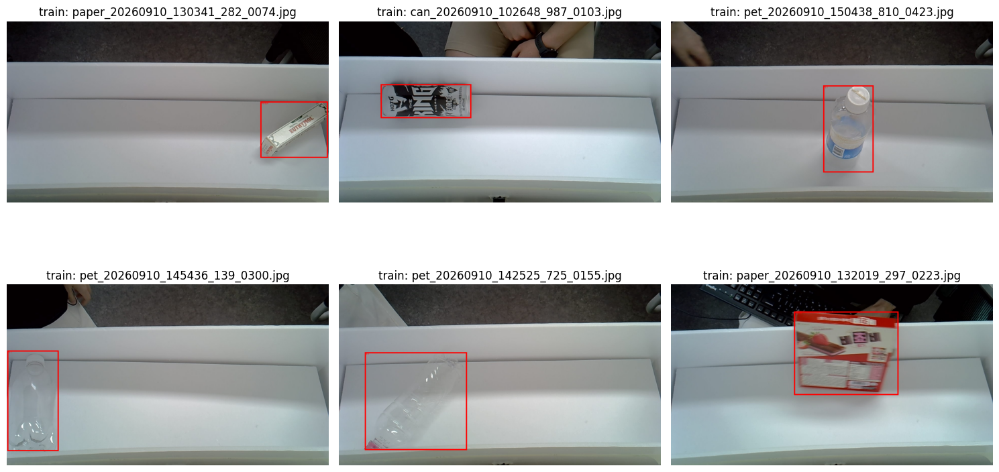

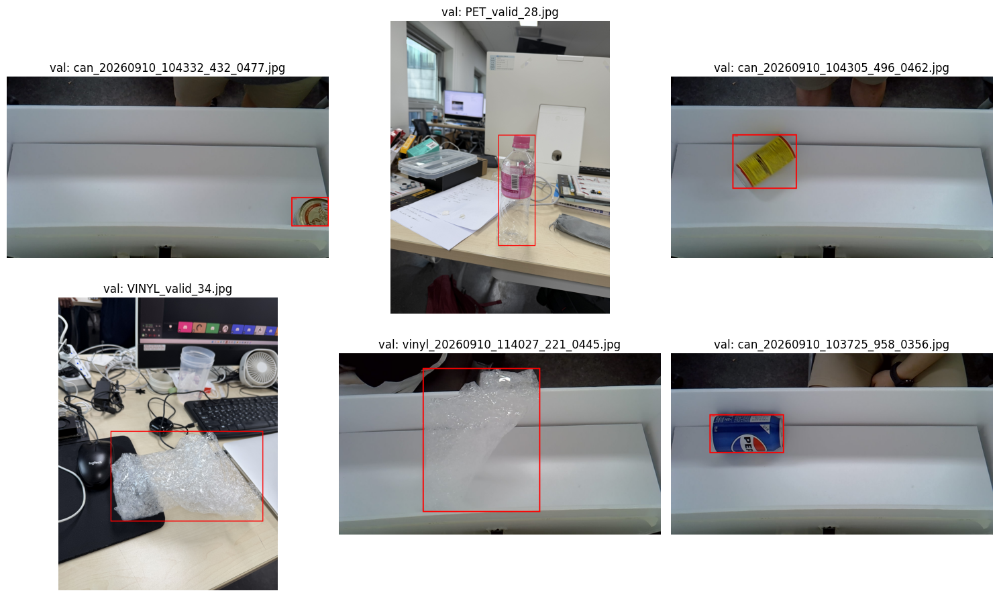

In [ ]:
import matplotlib.pyplot as plt
rng = random.Random(SEED)
for split in ('train', 'val'):
    selected = rng.sample(samples[split], min(6, len(samples[split])))
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    for ax in axes.flat:
        ax.axis('off')
    for ax, (p, boxes) in zip(axes.flat, selected):
        im = Image.open(p).convert('RGB')
        draw = ImageDraw.Draw(im)
        W,H = im.size
        for c,x,y,w,h in boxes:
            xy = ((x-w/2)*W,(y-h/2)*H,(x+w/2)*W,(y+h/2)*H)
            draw.rectangle(xy, outline='red', width=max(2,W//250))
            draw.text((xy[0],xy[1]), CLASSES[c], fill='red')
        ax.imshow(im)
        ax.set_title(f'{split}: {p.name}')
    plt.tight_layout()
    plt.show()

## 4. 다양한 각도·크기 학습
회전 ±45°, scale=0.5, mosaic=0.5를 사용하고 마지막 20 epoch에서 mosaic을 끕니다. 과도한 원근/상하반전과 mixup은 기본 비활성화했습니다. 작은 물체에 도움이 되도록 입력을 832로 높였으나 속도와 메모리 비용이 증가합니다.

In [ ]:
if DEVICE == 'cpu' and not ALLOW_CPU_TRAIN:
    raise RuntimeError('GPU 런타임을 선택하세요. CPU 실행을 원하면 ALLOW_CPU_TRAIN=True.')
SAVE_ROOT.mkdir(parents=True, exist_ok=True)
yolo = YOLO(MODEL)
train_args = dict(data=str(DATA), epochs=EPOCHS, patience=40, imgsz=IMGSZ,
    batch=BATCH, device=DEVICE, workers=2 if colab else 0,
    project=str(SAVE_ROOT), name=f'recycle_{Path(MODEL).stem}_{RUN_ID}',
    optimizer='AdamW', lr0=0.001, lrf=0.01, weight_decay=0.0005,
    cos_lr=True, warmup_epochs=3.0, seed=SEED, deterministic=True,
    amp=DEVICE != 'cpu', cache=False, degrees=45.0, translate=0.1, scale=0.5,
    shear=0.0, perspective=0.0, flipud=0.0, fliplr=0.5,
    hsv_h=0.01, hsv_s=0.3, hsv_v=0.25,
    mosaic=0.5, close_mosaic=20, mixup=0.0, copy_paste=0.0,
    val=True, plots=True, save=True, save_period=10, exist_ok=False)
train_results = yolo.train(**train_args)
RUN_DIR = Path(yolo.trainer.save_dir)
BEST = RUN_DIR/'weights'/'best.pt'
assert BEST.is_file(), f'best.pt가 없습니다: {RUN_DIR}'
print('학습 완료:', BEST)

New https://pypi.org/project/ultralytics/8.4.147 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.131 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=20, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/recycle_work/20260911_163755_629672/merged/data.yaml, degrees=45.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.3, hsv_v=0.25, imgsz=832, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, m

## 5. 전체·데이터 출처별 탐지 성능


In [ ]:
from pathlib import Path
from ultralytics import YOLO

save_root = Path(
    '/content/drive/MyDrive/ai/final/model_specific_domain2/runs'
)

best_files = sorted(
    save_root.rglob('best.pt'),
    key=lambda p: p.stat().st_mtime,
    reverse=True,
)

if not best_files:
    raise FileNotFoundError('Drive 연결과 best.pt 저장 여부를 확인하세요.')

for i, p in enumerate(best_files):
    print(f'[{i}] {p}')

MODEL_INDEX = 0  # 가장 최근 저장 모델. 다른 모델이면 번호 변경
BEST = best_files[MODEL_INDEX]
RUN_DIR = BEST.parent.parent

print('평가할 모델:', BEST)

[0] /content/drive/MyDrive/ai/final/model_specific_domain2/runs/runs/recycle_yolo11n_20260910_140031_376641-2/weights/best.pt
평가할 모델: /content/drive/MyDrive/ai/final/model_specific_domain2/runs/runs/recycle_yolo11n_20260910_140031_376641-2/weights/best.pt


old 원본 클래스: {0: 'PAPER', 1: 'CAN', 2: 'PET', 3: 'VINYL'} → {0: 0, 1: 1, 2: 2, 3: 3}
new 원본 클래스: {0: 'PAPER', 1: 'CAN', 2: 'PET', 3: 'VINYL'} → {0: 0, 1: 1, 2: 2, 3: 3}

[동일 이미지 라벨 충돌 → 두 번째 파일 유지]
제외: /content/recycle_work/20260912_025331_102281/extracted_new/specific_data2/train/CAN_train_112.jpg
유지: /content/recycle_work/20260912_025331_102281/extracted_new/specific_data2/train/CAN_train_111.jpg
분할: 제외=train, 유지=train

[동일 이미지 라벨 충돌 → 두 번째 파일 유지]
제외: /content/recycle_work/20260912_025331_102281/extracted_new/specific_data2/train/CAN_train_115.jpg
유지: /content/recycle_work/20260912_025331_102281/extracted_new/specific_data2/train/CAN_train_114.jpg
분할: 제외=train, 유지=train

[동일 이미지 라벨 충돌 → 두 번째 파일 유지]
제외: /content/recycle_work/20260912_025331_102281/extracted_new/specific_data2/train/CAN_train_118.jpg
유지: /content/recycle_work/20260912_025331_102281/extracted_new/specific_data2/train/CAN_train_117.jpg
분할: 제외=train, 유지=train

[동일 이미지 라벨 충돌 → 두 번째 파일 유지]
제외: /content/recycle_work/20260912_

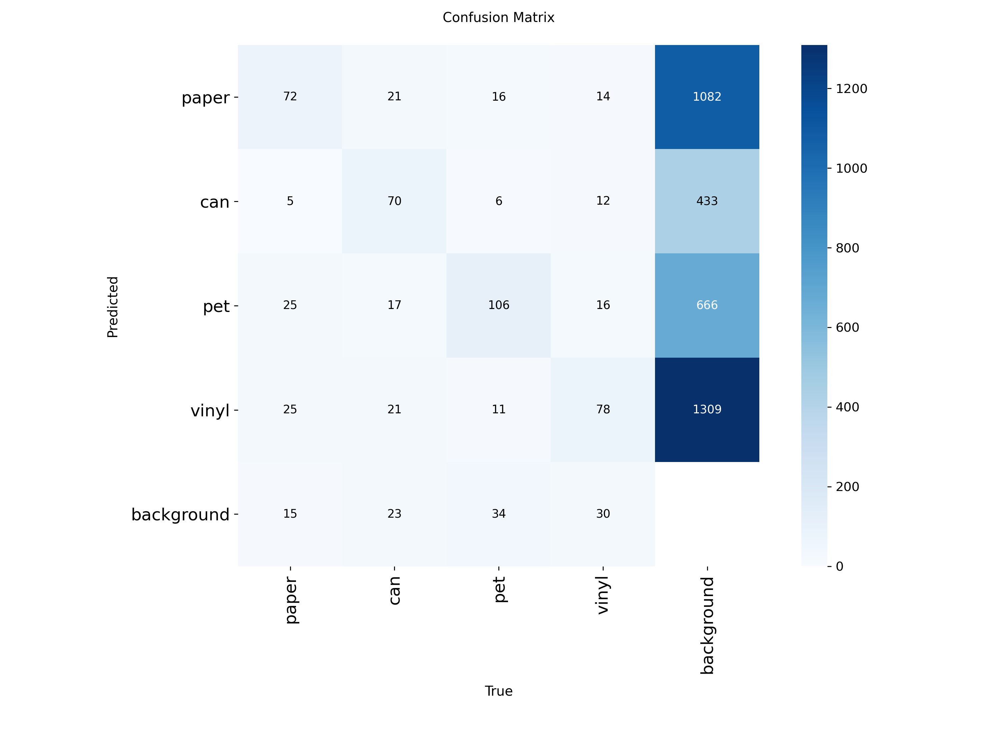

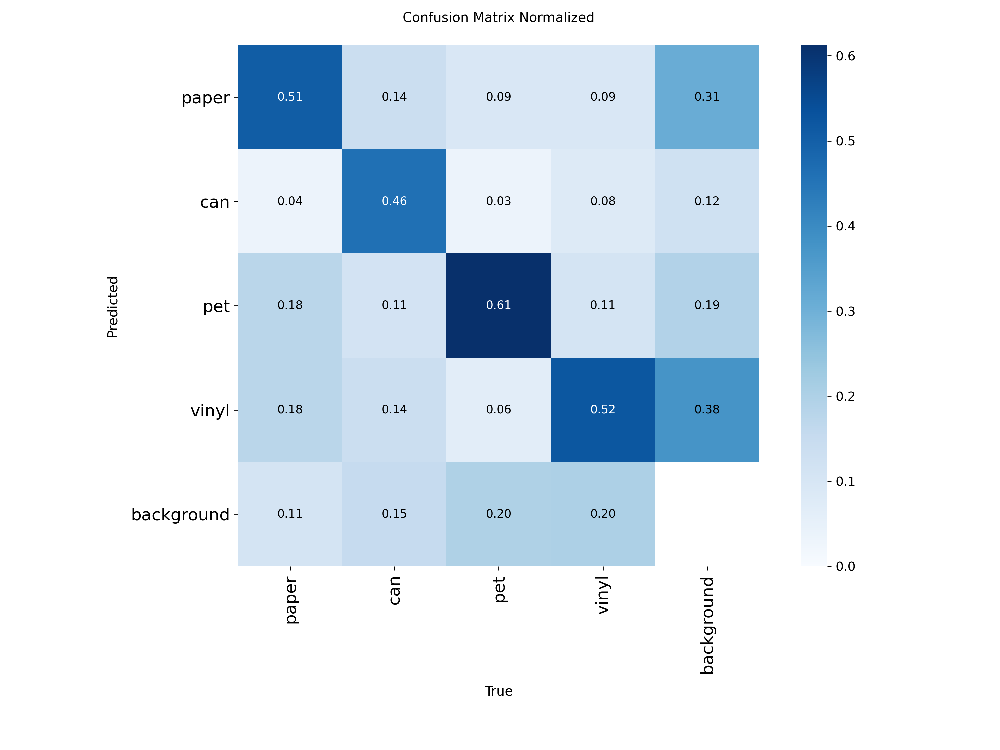

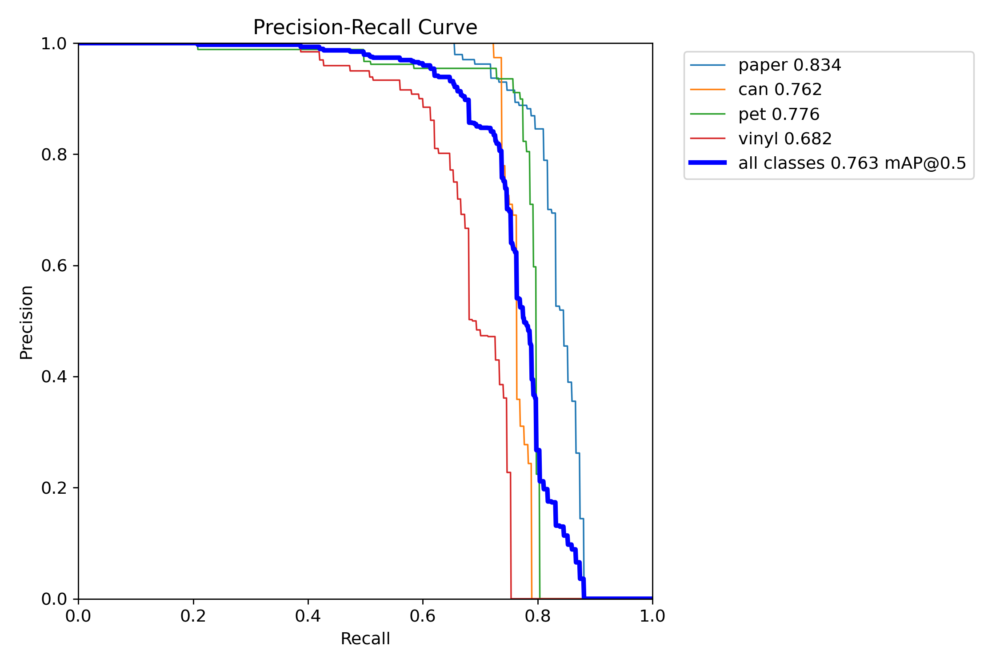

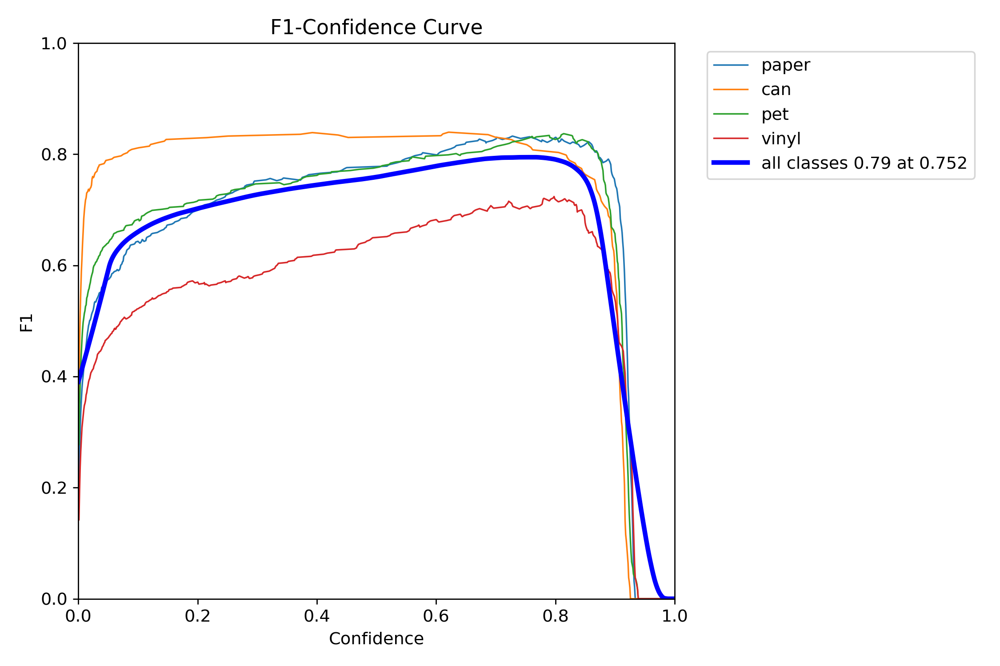

Ultralytics 8.4.131 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2588.7±762.7 MB/s, size: 91.6 KB)
val: Scanning /content/recycle_work/20260912_025331_102281/merged/labels/val/old... 463 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 463/463 1.5Kit/s 0.3s
val: New cache created: /content/recycle_work/20260912_025331_102281/merged/labels/val/old.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 58/58 21.0it/s 2.8s
                   all        463        463      0.958      0.969      0.986      0.871
                 paper        108        108      0.998      0.991      0.995       0.92
                   can        111        111      0.991      0.982      0.995      0.877
                   pet        134        134      0.907      0.985      0.979      0.855
                 vinyl        110        110      0.935      0.918      0.97

,split,source,images,precision,recall,mAP50,mAP50_95
0,val,all,617,0.8960,0.7185,0.7634,0.6648
1,val,old,463,0.9580,0.9691,0.9856,0.8712
2,val,new,154,0.3118,0.0746,0.0741,0.0536


,split,source,class_name,gt_boxes,precision,recall,F1,AP50,AP50_95
0,val,all,PAPER,142,0.8857,0.7817,0.8304,0.8336,0.7438
1,val,all,CAN,152,1.0000,0.6909,0.8172,0.7624,0.6619
2,val,all,PET,173,0.8892,0.7746,0.8279,0.7757,0.6700
3,val,all,VINYL,150,0.8093,0.6267,0.7064,0.6820,0.5833
4,val,old,PAPER,108,0.9985,0.9907,0.9946,0.9950,0.9198
5,val,old,CAN,111,0.9909,0.9823,0.9866,0.9949,0.8767
6,val,old,PET,134,0.9072,0.9851,0.9446,0.9794,0.8548
7,val,old,VINYL,110,0.9352,0.9181,0.9266,0.9732,0.8336
8,val,new,PAPER,34,0.3354,0.2229,0.2678,0.1921,0.1422
9,val,new,CAN,41,0.7385,0.0244,0.0472,0.0563,0.0334


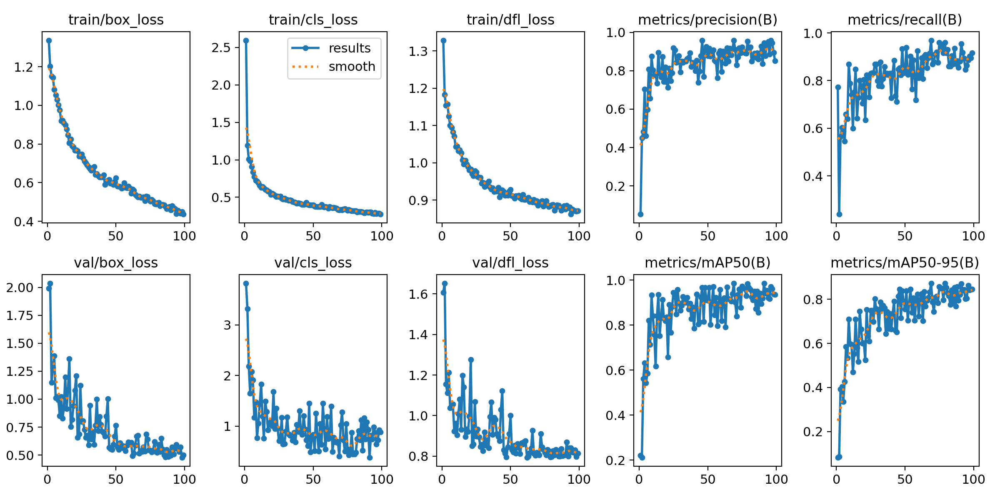

In [ ]:

RUN_ID, DATASET_ROOT, DATA, records = merge_datasets(SOURCES, WORK_ROOT)

samples = {
    s: [
        (Path(r['image']), r['boxes'])
        for r in records if r['split'] == s
    ]
    for s in ['train', 'val', 'test']
}

yolo_best = YOLO(str(BEST))
REPORT_DIR = RUN_DIR/'reports'
REPORT_DIR.mkdir(exist_ok=True)
evaluation_rows=[]
class_rows=[]
for split in ['val','test']:
    if not samples[split]: continue
    for source in ['all','old','new']:
        subset=[r for r in records if r['split']==split and (source=='all' or r['source']==source)]
        if not subset: continue
        name=f'{split}_{source}'
        listing=REPORT_DIR/f'{name}_images.txt'
        listing.write_text('\n'.join(r['image'] for r in subset)+'\n', encoding='utf-8')
        cfg=yaml.safe_load(DATA.read_text())
        cfg[split]=listing.as_posix()
        eval_yaml=REPORT_DIR/f'{name}.yaml'
        eval_yaml.write_text(yaml.safe_dump(cfg), encoding='utf-8')
        metrics=yolo_best.val(data=str(eval_yaml), split=split, imgsz=DEPLOY_IMGSZ, batch=BATCH,
            device=DEVICE, conf=0.001, iou=0.7, max_det=300, plots=True,
            project=str(REPORT_DIR), name=name, exist_ok=True)
        evaluation_rows.append(dict(split=split, source=source, images=len(subset),
            precision=float(metrics.box.mp), recall=float(metrics.box.mr),
            mAP50=float(metrics.box.map50), mAP50_95=float(metrics.box.map)))
        by_id={int(cid):metrics.box.class_result(j) for j,cid in enumerate(metrics.box.ap_class_index)}
        counts=Counter(b[0] for r in subset for b in r['boxes'])
        for cid,c in enumerate(CLASSES):
            p,r,a,b=by_id.get(cid, [float('nan')]*4)
            class_rows.append(dict(split=split,source=source,class_name=c,gt_boxes=counts[cid],
                precision=float(p),recall=float(r),F1=float(2*p*r/(p+r)) if p+r>0 else (0.0 if p+r==0 else float('nan')),
                AP50=float(a),AP50_95=float(b)))
        if source=='all':
            for filename in ['confusion_matrix.png','confusion_matrix_normalized.png','BoxPR_curve.png','BoxF1_curve.png']:
                path=Path(metrics.save_dir)/filename
                if path.is_file(): display(Image.open(path))
overall=pd.DataFrame(evaluation_rows)
per_class=pd.DataFrame(class_rows)
print('지표 범위: 0~1 (1 = 100%)')
display(overall.round(4)); display(per_class.round(4))
overall.to_csv(REPORT_DIR/'overall.csv',index=False)
per_class.to_csv(REPORT_DIR/'per_class.csv',index=False)
if (RUN_DIR/'results.png').is_file(): display(Image.open(RUN_DIR/'results.png'))

## 6. 운영 임계값에서 TP / FP / FN · 크기별 재현율


In [ ]:
def box_iou_one(a, b):
    left=np.maximum(a[:2],b[:2]); right=np.minimum(a[2:],b[2:])
    intersection=np.prod(np.maximum(0,right-left))
    aa=np.prod(np.maximum(0,a[2:]-a[:2])); bb=np.prod(np.maximum(0,b[2:]-b[:2]))
    return float(intersection/max(aa+bb-intersection,1e-12))

def match_detections(gt, predictions, threshold):
    used=set(); matches=[]; false_positives=[]
    for pred in sorted(predictions, key=lambda v: -v[1]):
        candidates=[(box_iou_one(np.array(pred[2:]),np.array(g[1:])),j)
                    for j,g in enumerate(gt) if j not in used and int(g[0])==int(pred[0])]
        best=max(candidates, default=(0,-1))
        if best[1]>=0 and best[0]>=threshold:
            used.add(best[1]); matches.append(best[1])
        else: false_positives.append(int(pred[0]))
    return matches,false_positives,[j for j in range(len(gt)) if j not in used]

operating=[]; sizes=[]; errors=[]
for split in ['val','test']:
    rr=[r for r in records if r['split']==split]
    if not rr: continue
    counts=Counter(); size_counts=Counter()
    for rec in rr:
        gt=[]; buckets=[]
        for c,x,y,w,h in rec['boxes']:
            gt.append([c,x-w/2,y-h/2,x+w/2,y+h/2])
            buckets.append('small_<1%' if w*h<0.01 else 'medium_1-10%' if w*h<0.1 else 'large_>=10%')
        result=yolo_best.predict(rec['image'],imgsz=DEPLOY_IMGSZ,conf=INFER_CONF,iou=0.7,max_det=300,device=DEVICE,verbose=False)[0]
        preds=[[int(c),float(score),*box] for c,score,box in zip(result.boxes.cls.cpu().tolist(),result.boxes.conf.cpu().tolist(),result.boxes.xyxyn.cpu().tolist())]
        matched,fp,fn=match_detections(gt,preds,MATCH_IOU)
        for source in ['all',rec['source']]:
            for j in matched: counts[(source,int(gt[j][0]),'TP')]+=1
            for c in fp: counts[(source,c,'FP')]+=1
            for j in fn: counts[(source,int(gt[j][0]),'FN')]+=1
            for j,bucket in enumerate(buckets):
                size_counts[(source,bucket,'GT')]+=1
                if j in matched: size_counts[(source,bucket,'TP')]+=1
        if fp or fn:
            errors.append(dict(split=split,source=rec['source'],image=rec['image'],FP=len(fp),FN=len(fn)))
            if sum(e['split']==split for e in errors)<=30:
                canvas=Image.fromarray(result.plot()[...,::-1]); draw=ImageDraw.Draw(canvas)
                for c,x1,y1,x2,y2 in gt:
                    xy=(x1*canvas.width,y1*canvas.height,x2*canvas.width,y2*canvas.height)
                    draw.rectangle(xy,outline='yellow',width=3)
                    draw.text(xy[:2], 'GT '+CLASSES[int(c)],fill='yellow')
                canvas.save(REPORT_DIR/f'error_{split}_{len(errors):05d}.jpg')
    for source in ['all','old','new']:
        if not any(r['source']==source or source=='all' for r in rr): continue
        for cid,c in list(enumerate(CLASSES))+[(-1,'ALL_MICRO')]:
            ids=range(len(CLASSES)) if cid==-1 else [cid]
            tp,fp,fn=[sum(counts[(source,i,k)] for i in ids) for k in ['TP','FP','FN']]
            operating.append(dict(split=split,source=source,class_name=c,conf=INFER_CONF,match_iou=MATCH_IOU,
                TP=tp,FP=fp,FN=fn,precision=tp/(tp+fp) if tp+fp else float('nan'),
                recall=tp/(tp+fn) if tp+fn else float('nan'),F1=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else float('nan')))
        for bucket in ['small_<1%','medium_1-10%','large_>=10%']:
            n=size_counts[(source,bucket,'GT')]; tp=size_counts[(source,bucket,'TP')]
            sizes.append(dict(split=split,source=source,size=bucket,GT=n,TP=tp,recall=tp/n if n else float('nan')))
for filename,rows in [('operating_metrics',operating),('size_recall',sizes),('errors',errors)]:
    table=pd.DataFrame(rows); table.to_csv(REPORT_DIR/f'{filename}.csv',index=False)
    display(table.head(50))
print('오류 예시의 노란 박스: 정답 / 나머지 박스: 예측')

,split,source,class_name,conf,match_iou,TP,FP,FN,precision,recall,F1
0,val,all,PAPER,0.25,0.5,115,85,27,0.575000,0.809859,0.672515
1,val,all,CAN,0.25,0.5,112,5,40,0.957265,0.736842,0.832714
2,val,all,PET,0.25,0.5,137,54,36,0.717277,0.791908,0.752747
3,val,all,VINYL,0.25,0.5,107,65,43,0.622093,0.713333,0.664596
4,val,all,ALL_MICRO,0.25,0.5,471,209,146,0.692647,0.763371,0.726291
5,val,old,PAPER,0.25,0.5,107,1,1,0.990741,0.990741,0.990741
6,val,old,CAN,0.25,0.5,110,2,1,0.982143,0.990991,0.986547
7,val,old,PET,0.25,0.5,133,18,1,0.880795,0.992537,0.933333
8,val,old,VINYL,0.25,0.5,106,12,4,0.898305,0.963636,0.929825
9,val,old,ALL_MICRO,0.25,0.5,456,33,7,0.932515,0.984881,0.957983


,split,source,size,GT,TP,recall
0,val,all,small_<1%,3,1,0.333333
1,val,all,medium_1-10%,394,326,0.827411
2,val,all,large_>=10%,220,144,0.654545
3,val,old,small_<1%,2,1,0.500000
4,val,old,medium_1-10%,318,317,0.996855
5,val,old,large_>=10%,143,138,0.965035
6,val,new,small_<1%,1,0,0.000000
7,val,new,medium_1-10%,76,9,0.118421
8,val,new,large_>=10%,77,6,0.077922


,split,source,image,FP,FN
0,val,old,/content/recycle_work/20260912_025331_102281/m...,1,1
1,val,old,/content/recycle_work/20260912_025331_102281/m...,1,0
2,val,old,/content/recycle_work/20260912_025331_102281/m...,1,0
3,val,old,/content/recycle_work/20260912_025331_102281/m...,1,0
4,val,old,/content/recycle_work/20260912_025331_102281/m...,1,0
5,val,old,/content/recycle_work/20260912_025331_102281/m...,1,1
6,val,old,/content/recycle_work/20260912_025331_102281/m...,1,0
7,val,old,/content/recycle_work/20260912_025331_102281/m...,1,0
8,val,old,/content/recycle_work/20260912_025331_102281/m...,1,0
9,val,old,/content/recycle_work/20260912_025331_102281/m...,1,1


오류 예시의 노란 박스: 정답 / 나머지 박스: 예측


## 7. 예측 미리보기 및 새 사진


0: 640x640 1 paper, 9.2ms
1: 640x640 1 can, 9.2ms
2: 640x640 1 pet, 9.2ms
3: 640x640 1 pet, 9.2ms
4: 640x640 1 pet, 9.2ms
5: 640x640 1 paper, 9.2ms
6: 640x640 1 can, 9.2ms
7: 640x640 1 paper, 9.2ms


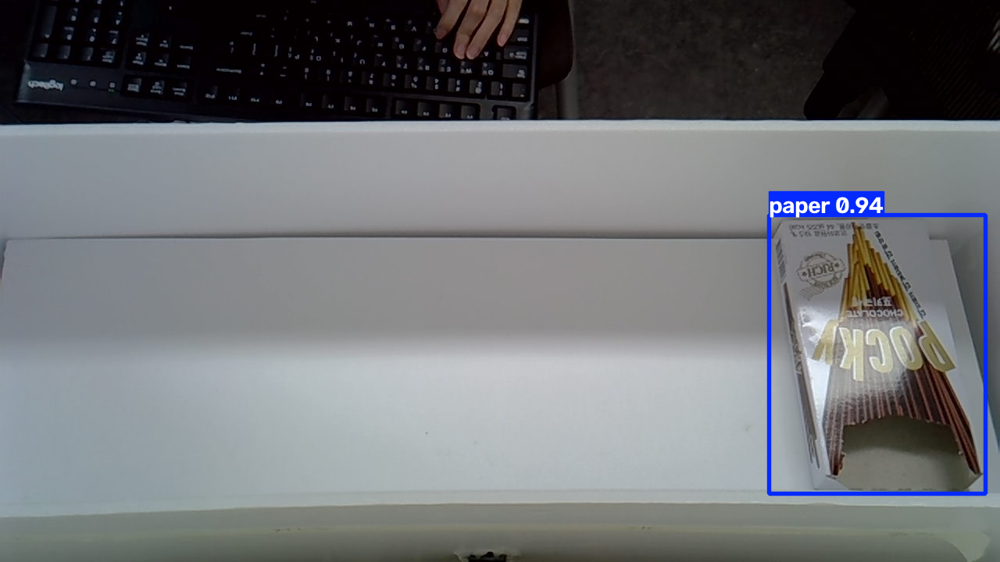

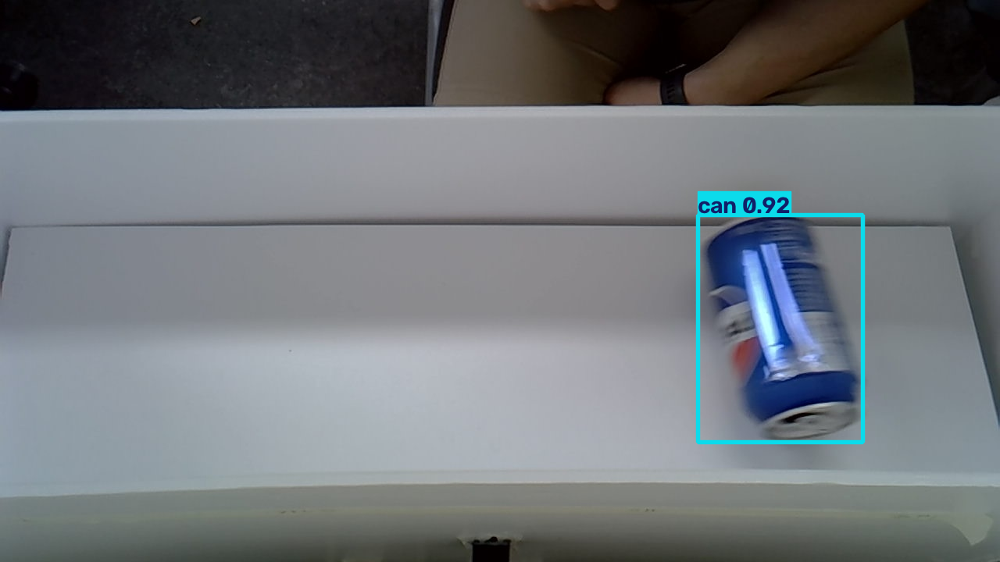

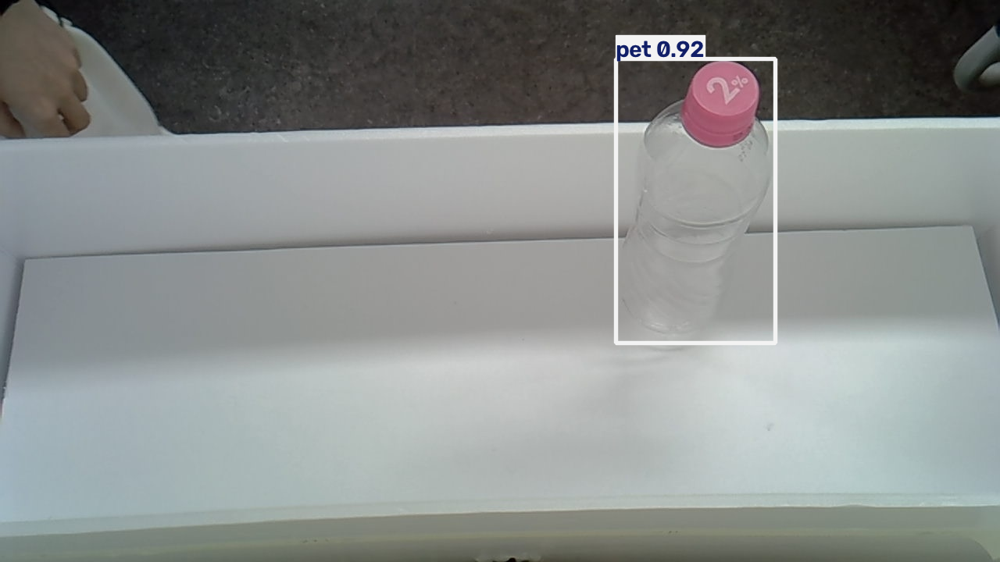

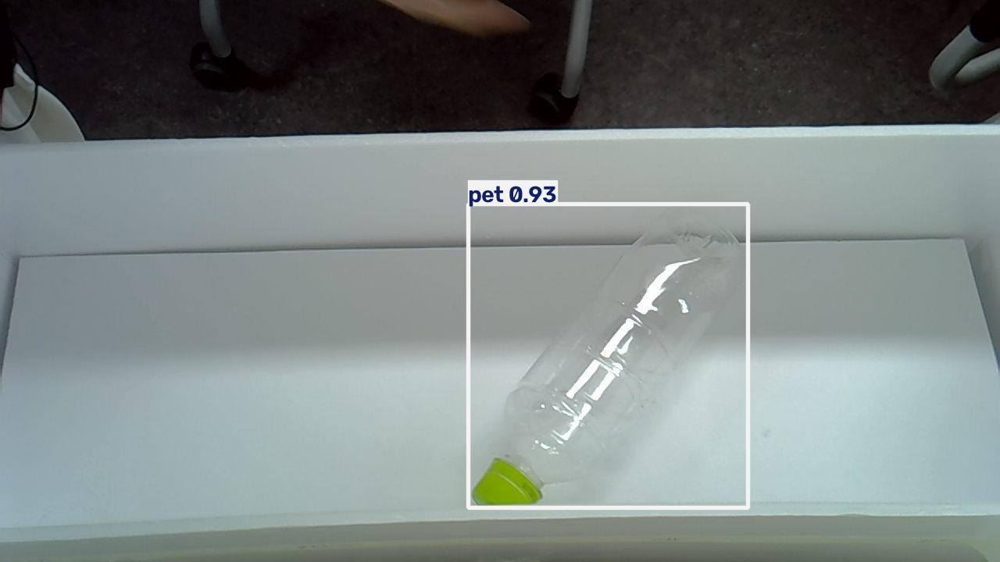

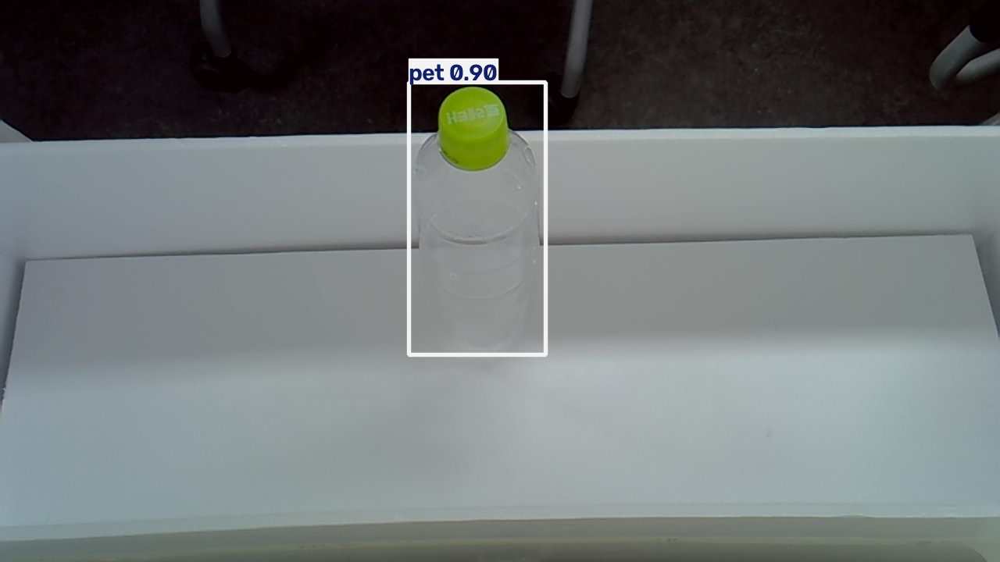

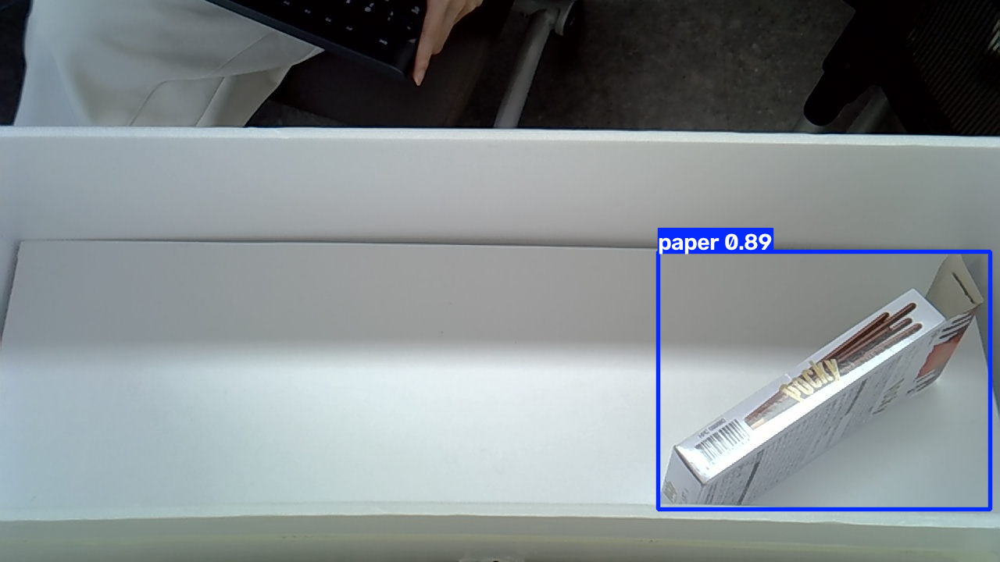

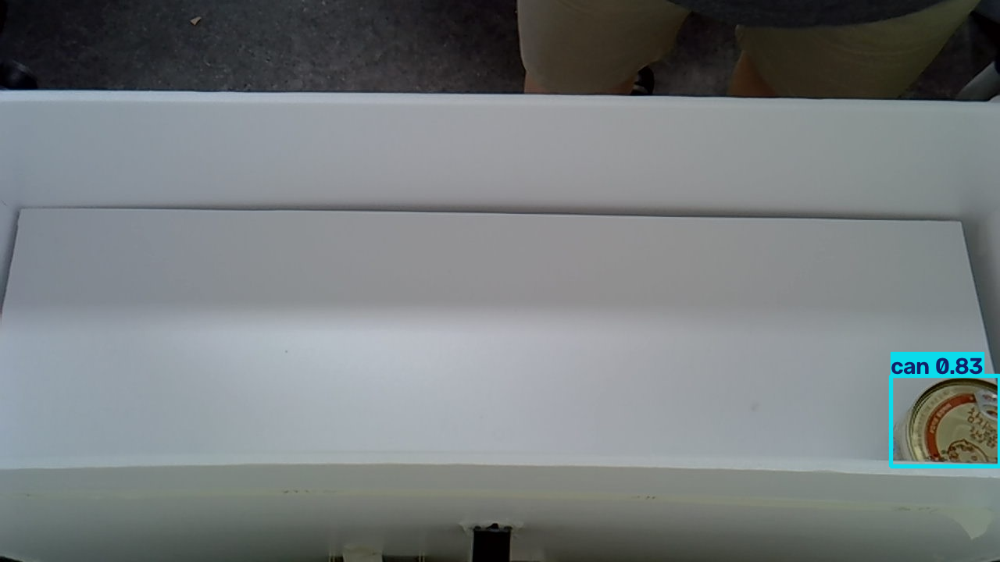

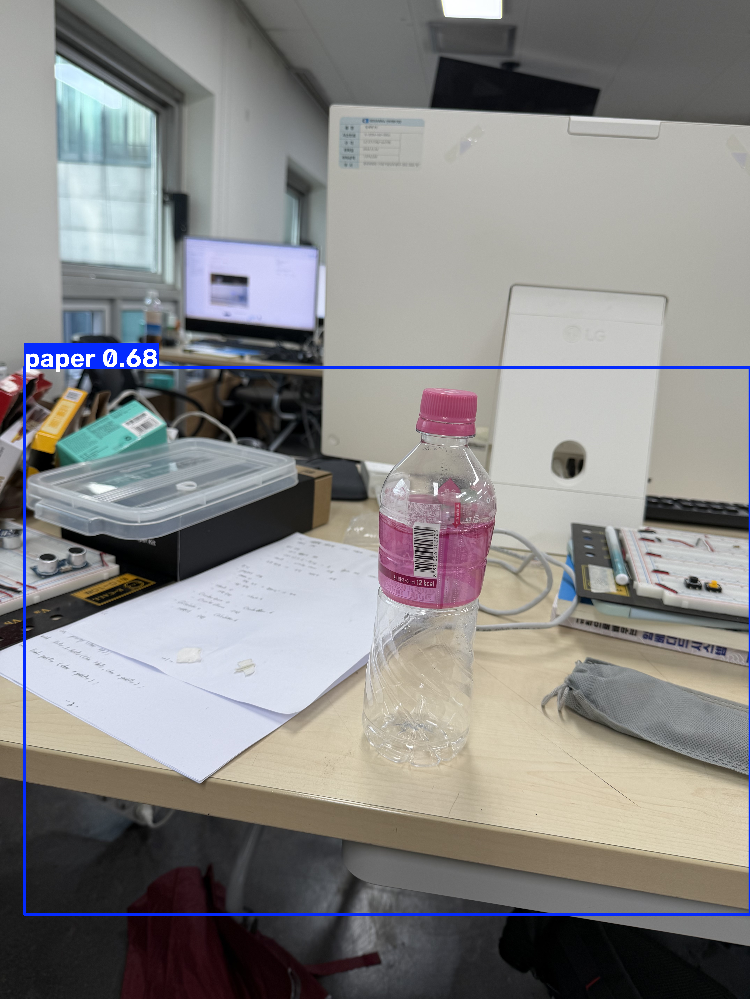

Speed: 2.5ms preprocess, 9.2ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/drive/MyDrive/ai/final/model_specific_domain2/runs/runs/recycle_yolo11n_20260910_140031_376641-2/predictions-2


In [ ]:
import random
rng = random.Random(42)

preview = [str(p) for p,_ in rng.sample(samples['val'], min(8,len(samples['val'])))]
for result in yolo_best.predict(source=preview, imgsz=DEPLOY_IMGSZ, conf=INFER_CONF,
        device=DEVICE, save=True, project=str(RUN_DIR), name='predictions', stream=True):
    display(Image.fromarray(result.plot()[..., ::-1]))
# 새 사진/폴더를 지정하면 박스와 클래스를 예측합니다.
NEW_SOURCE = None  # 예: '/content/drive/MyDrive/new_images'
if NEW_SOURCE is not None:
    for result in yolo_best.predict(source=NEW_SOURCE, imgsz=DEPLOY_IMGSZ, conf=INFER_CONF,
            device=DEVICE, save=True, project=str(RUN_DIR), name='new_images', stream=True):
        print(result.path, result.boxes.cls.tolist(), result.boxes.conf.tolist())

## 8. 모델·설정·보고서 저장 및 ONNX

In [ ]:
import json
import pandas as pd
from collections import Counter

import yaml

args_path = RUN_DIR / 'args.yaml'

if args_path.is_file():
    train_args = yaml.safe_load(
        args_path.read_text(encoding='utf-8')
    )
    print('실제 학습 설정 복구:', args_path)
else:
    train_args = None
    print('args.yaml이 없어 학습 설정은 null로 기록합니다.')

manifest_path = DATASET_ROOT / 'manifest.json'
manifest_records = json.loads(
    manifest_path.read_text(encoding='utf-8')
)

rows = []
sources = sorted({r['source'] for r in manifest_records})

for source in sources:
    for split in ['train', 'val', 'test']:
        subset = [
            r for r in manifest_records
            if r['source'] == source and r['split'] == split
        ]
        counts = Counter(
            int(box[0])
            for r in subset
            for box in r['boxes']
        )

        rows.append({
            'source': source,
            'split': split,
            'images': len(subset),
            'backgrounds': sum(not r['boxes'] for r in subset),
            **{
                name: counts[cid]
                for cid, name in enumerate(CLASSES)
            },
        })

summary = pd.DataFrame(rows)
output_path = DATASET_ROOT / 'dataset_counts.csv'
summary.to_csv(output_path, index=False)

display(summary)
print('요약 파일 복구 완료:', output_path)

실제 학습 설정 복구: /content/drive/MyDrive/ai/final/model_specific_domain2/runs/runs/recycle_yolo11n_20260910_140031_376641-2/args.yaml


,source,split,images,backgrounds,PAPER,CAN,PET,VINYL
0,new,train,633,1,136,175,159,162
1,new,val,154,0,34,41,39,40
2,new,test,0,0,0,0,0,0
3,old,train,1780,0,412,423,536,410
4,old,val,463,0,108,111,134,110
5,old,test,0,0,0,0,0,0


요약 파일 복구 완료: /content/recycle_work/20260912_025331_102281/merged/dataset_counts.csv


In [ ]:
shutil.copy2(DATASET_ROOT/'manifest.json', REPORT_DIR/'manifest.json')
shutil.copy2(DATASET_ROOT/'dataset_counts.csv', REPORT_DIR/'dataset_counts.csv')
shutil.copy2(DATASET_ROOT/'duplicates_removed.csv', REPORT_DIR/'duplicates_removed.csv')
(REPORT_DIR/'reproducibility.json').write_text(json.dumps(dict(
    ultralytics=ultralytics.__version__,torch=torch.__version__,sources=SOURCES,
    train_args=train_args,deploy_imgsz=DEPLOY_IMGSZ,conf=INFER_CONF,match_iou=MATCH_IOU,
    note='val is model-selection data; test coverage depends on supplied ZIPs'),
    ensure_ascii=False,indent=2,default=str),encoding='utf-8')
print('best_2.pt:',BEST)
print('보고서/그래프/오류 예시:',REPORT_DIR)
if EXPORT_ONNX:
    try:
        exported=yolo_best.export(format='onnx',imgsz=DEPLOY_IMGSZ,batch=1,dynamic=False,simplify=False,opset=17)
        print('ONNX:',exported)
    except Exception as e:
        print('학습·평가는 저장되었습니다. ONNX 변환 실패:',repr(e))

best.pt: /content/drive/MyDrive/ai/final/model_specific_domain2/runs/runs/recycle_yolo11n_20260910_140031_376641-2/weights/best.pt
보고서/그래프/오류 예시: /content/drive/MyDrive/ai/final/model_specific_domain2/runs/runs/recycle_yolo11n_20260910_140031_376641-2/reports
Ultralytics 8.4.131 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.20GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino

PyTorch: starting from '/content/drive/MyDrive/ai/final/model_specific_domain2/runs/runs/recycle_yolo11n_20260910_140031_376641-2/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 8, 8400) (5.2 MB)
requirements: Ultralytics requirement ['onnx>=1.12.0,<2.0.0'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 5 packages in 334ms
Prepared 1 package in 559ms
Installed 1 package in 247ms
 + onnx==1.22.0

requirements: AutoUpdate success ✅ 1.6s
